# Validación sintética de ecuaciones diferenciales

## Proyecto

**Descubrimiento de ecuaciones dinámicas en estrellas variables mediante TESS, SINDy y Neural ODE**

## Objetivo del notebook

Validar progresivamente la integración, reconstrucción y posterior identificación de ecuaciones diferenciales conocidas antes de trabajar con curvas de luz observacionales de TESS.

## Sistemas previstos

1. Oscilador armónico.
2. Oscilador amortiguado.
3. Oscilador de Duffing.
4. Oscilador de Van der Pol.
5. Identificación posterior mediante SINDy.

## Regla científica

En esta etapa conocemos las ecuaciones verdaderas. Esto permitirá comprobar si los métodos posteriores recuperan correctamente su estructura y sus parámetros.

In [1]:
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.integrate import solve_ivp

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"SciPy: {scipy.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")

Python: 3.11.17
NumPy: 2.4.6
SciPy: 1.17.1
Matplotlib: 3.11.2


## 1. Oscilador armónico

La ecuación diferencial de segundo orden es:

\[
\ddot{x}+\omega_0^2x=0.
\]

Definimos una nueva variable:

\[
v=\dot{x}.
\]

Entonces el sistema equivalente de primer orden es:

\[
\dot{x}=v,
\]

\[
\dot{v}=-\omega_0^2x.
\]

Utilizaremos:

\[
\omega_0=2\pi,\qquad x(0)=1,\qquad v(0)=0.
\]

El periodo teórico es:

\[
T=\frac{2\pi}{\omega_0}=1.
\]

In [2]:
omega_0 = 2 * np.pi

x0 = 1.0
v0 = 0.0

initial_state = [x0, v0]

t_start = 0.0
t_end = 10.0
dt = 0.01

t_eval = np.arange(t_start, t_end + dt, dt)

theoretical_period = 2 * np.pi / omega_0

print(f"Frecuencia angular: {omega_0:.6f} rad/unidad de tiempo")
print(f"Periodo teórico: {theoretical_period:.6f}")
print(f"Número de puntos: {len(t_eval)}")
print(f"Condición inicial: x(0)={x0}, v(0)={v0}")

Frecuencia angular: 6.283185 rad/unidad de tiempo
Periodo teórico: 1.000000
Número de puntos: 1001
Condición inicial: x(0)=1.0, v(0)=0.0


In [4]:
def harmonic_oscillator(t, state, omega):
    """
    Sistema de primer orden equivalente a un oscilador armónico.

    Parámetros
    ----------
    t : float
        Tiempo actual. El sistema es autónomo, por lo que la derivada
        no depende explícitamente de t.
    state : array-like
        Estado actual [x, v].
    omega : float
        Frecuencia angular natural.

    Retorna
    -------
    list
        Derivadas [dx/dt, dv/dt].
    """
    x, v = state

    dx_dt = v
    dv_dt = -(omega**2) * x

    return [dx_dt, dv_dt]

In [5]:
initial_derivative = harmonic_oscillator(
    t=t_start,
    state=initial_state,
    omega=omega_0,
)

print("Derivada inicial:", initial_derivative)

Derivada inicial: [0.0, -39.47841760435743]


In [6]:
solution = solve_ivp(
    fun=harmonic_oscillator,
    t_span=(t_start, t_end),
    y0=initial_state,
    t_eval=t_eval,
    args=(omega_0,),
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)

print("Integración exitosa:", solution.success)
print("Mensaje del solucionador:", solution.message)
print("Puntos calculados:", len(solution.t))

Integración exitosa: True
Mensaje del solucionador: The solver successfully reached the end of the integration interval.
Puntos calculados: 1001


In [7]:
time = solution.t
position = solution.y[0]
velocity = solution.y[1]

print("Forma del tiempo:", time.shape)
print("Forma de la posición:", position.shape)
print("Forma de la velocidad:", velocity.shape)

Forma del tiempo: (1001,)
Forma de la posición: (1001,)
Forma de la velocidad: (1001,)


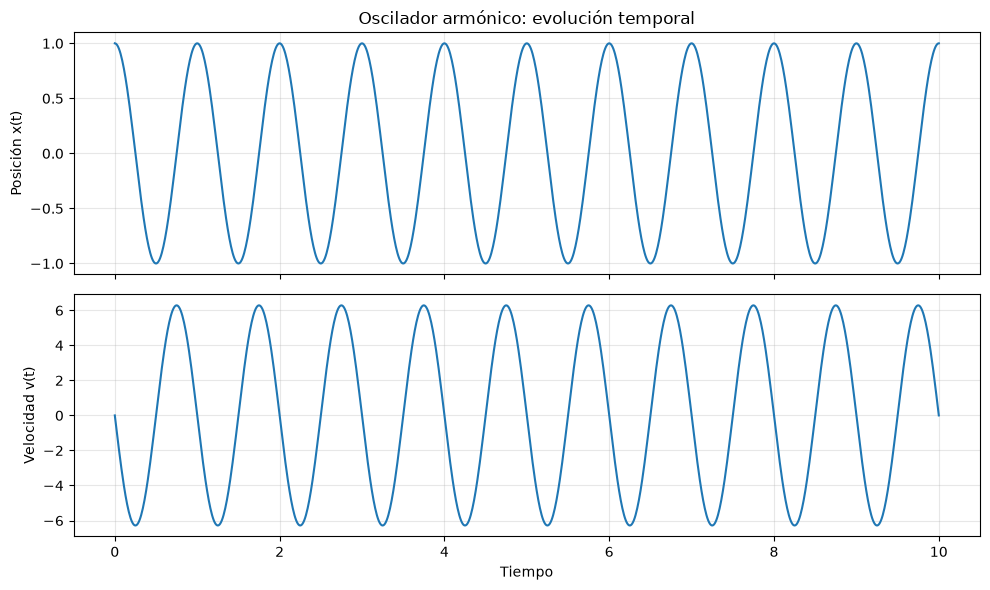

In [8]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(10, 6),
    sharex=True,
)

axes[0].plot(time, position)
axes[0].set_ylabel("Posición x(t)")
axes[0].set_title("Oscilador armónico: evolución temporal")
axes[0].grid(alpha=0.3)

axes[1].plot(time, velocity)
axes[1].set_xlabel("Tiempo")
axes[1].set_ylabel("Velocidad v(t)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

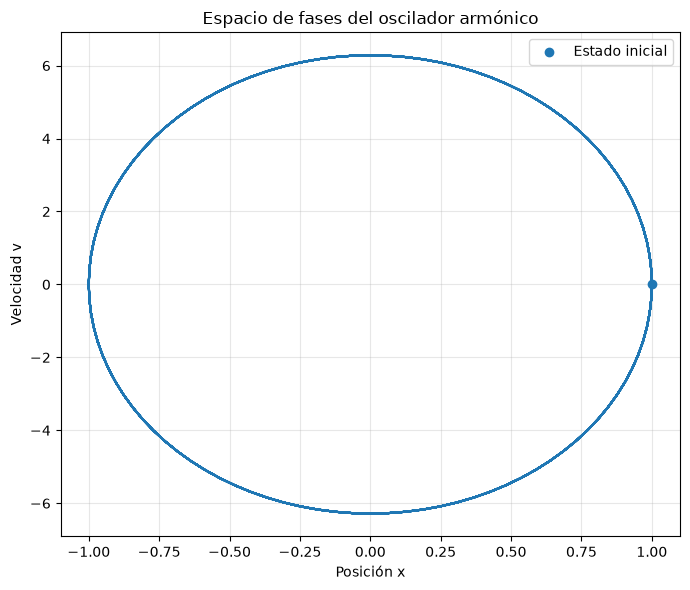

In [9]:
plt.figure(figsize=(7, 6))

plt.plot(position, velocity)
plt.scatter(
    position[0],
    velocity[0],
    label="Estado inicial",
    zorder=3,
)

plt.xlabel("Posición x")
plt.ylabel("Velocidad v")
plt.title("Espacio de fases del oscilador armónico")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
position_exact = np.cos(omega_0 * time)
velocity_exact = -omega_0 * np.sin(omega_0 * time)

position_error = position - position_exact
velocity_error = velocity - velocity_exact

max_position_error = np.max(np.abs(position_error))
max_velocity_error = np.max(np.abs(velocity_error))

print(f"Error máximo en posición: {max_position_error:.3e}")
print(f"Error máximo en velocidad: {max_velocity_error:.3e}")

Error máximo en posición: 4.615e-10
Error máximo en velocidad: 2.885e-09


In [11]:
energy = 0.5 * velocity**2 + 0.5 * omega_0**2 * position**2

initial_energy = energy[0]

relative_energy_error = (
    np.abs(energy - initial_energy) / np.abs(initial_energy)
)

maximum_relative_energy_error = np.max(relative_energy_error)

print(f"Energía inicial: {initial_energy:.10f}")
print(
    "Error relativo máximo de energía:",
    f"{maximum_relative_energy_error:.3e}",
)

Energía inicial: 19.7392088022
Error relativo máximo de energía: 4.565e-10


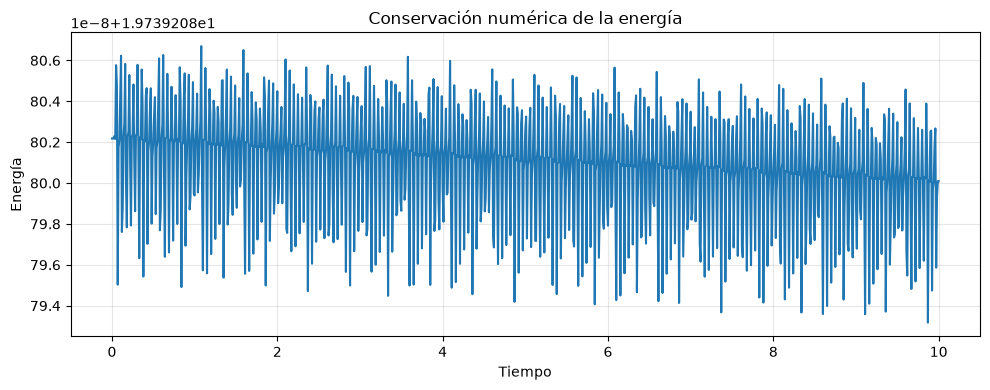

In [12]:
plt.figure(figsize=(10, 4))

plt.plot(time, energy)
plt.xlabel("Tiempo")
plt.ylabel("Energía")
plt.title("Conservación numérica de la energía")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
assert solution.success
assert max_position_error < 1e-7
assert maximum_relative_energy_error < 1e-7

print("VALIDACIÓN DEL OSCILADOR ARMÓNICO SUPERADA")

VALIDACIÓN DEL OSCILADOR ARMÓNICO SUPERADA


## 2. Oscilador armónico amortiguado

La ecuación diferencial es:

\[
\ddot{x}+2\zeta\omega_0\dot{x}+\omega_0^2x=0.
\]

Como sistema de primer orden:

\[
\dot{x}=v,
\]

\[
\dot{v}=-2\zeta\omega_0v-\omega_0^2x.
\]

Para \(0<\zeta<1\), el sistema es subamortiguado: continúa oscilando,
pero su amplitud disminuye con el tiempo.

In [14]:
def damped_oscillator(t, state, omega, damping_ratio):
    """
    Oscilador armónico con amortiguamiento lineal.

    state = [x, v]

    Ecuación:
        x'' + 2*zeta*omega*x' + omega^2*x = 0
    """
    x, v = state

    dx_dt = v
    dv_dt = (
        -2.0 * damping_ratio * omega * v
        - omega**2 * x
    )

    return [dx_dt, dv_dt]

In [15]:
damping_ratio = 0.10

initial_derivative_damped = damped_oscillator(
    t=t_start,
    state=initial_state,
    omega=omega_0,
    damping_ratio=damping_ratio,
)

print(f"Razón de amortiguamiento: {damping_ratio}")
print("Derivada inicial:", initial_derivative_damped)

Razón de amortiguamiento: 0.1
Derivada inicial: [0.0, -39.47841760435743]


In [16]:
damped_solution = solve_ivp(
    fun=damped_oscillator,
    t_span=(t_start, t_end),
    y0=initial_state,
    t_eval=t_eval,
    args=(omega_0, damping_ratio),
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)

print("Integración exitosa:", damped_solution.success)
print("Mensaje:", damped_solution.message)

Integración exitosa: True
Mensaje: The solver successfully reached the end of the integration interval.


In [17]:
damped_time = damped_solution.t
damped_position = damped_solution.y[0]
damped_velocity = damped_solution.y[1]

print("Puntos calculados:", len(damped_time))

Puntos calculados: 1001


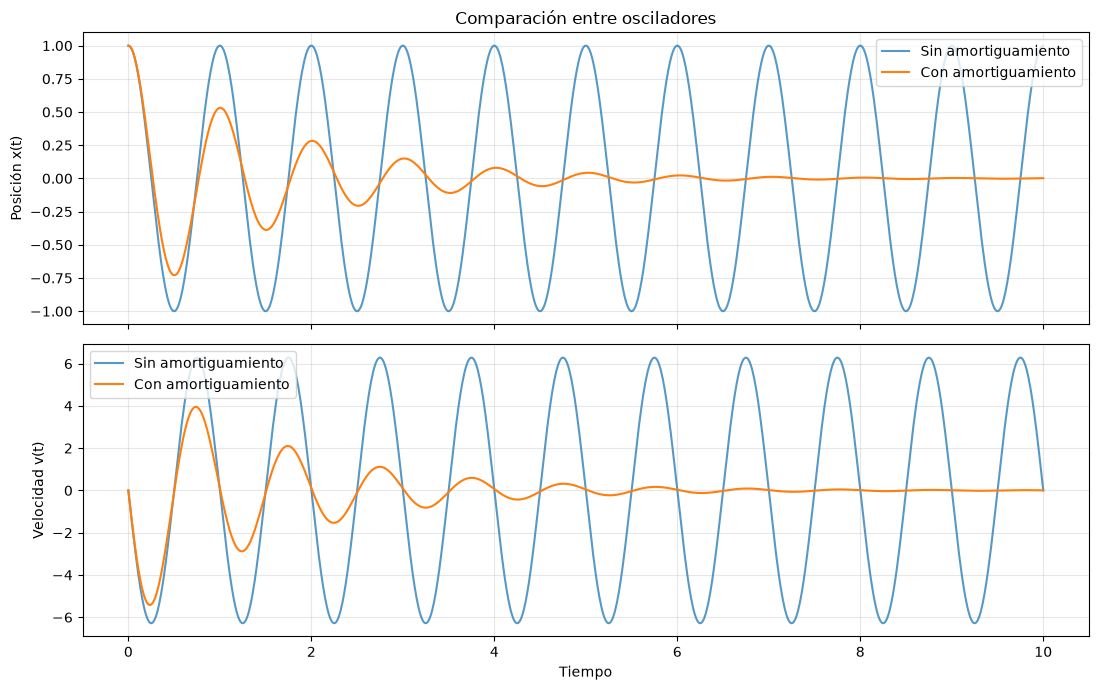

In [18]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(11, 7),
    sharex=True,
)

axes[0].plot(
    time,
    position,
    label="Sin amortiguamiento",
    alpha=0.75,
)

axes[0].plot(
    damped_time,
    damped_position,
    label="Con amortiguamiento",
)

axes[0].set_ylabel("Posición x(t)")
axes[0].set_title("Comparación entre osciladores")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    time,
    velocity,
    label="Sin amortiguamiento",
    alpha=0.75,
)

axes[1].plot(
    damped_time,
    damped_velocity,
    label="Con amortiguamiento",
)

axes[1].set_xlabel("Tiempo")
axes[1].set_ylabel("Velocidad v(t)")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [19]:
damped_frequency = omega_0 * np.sqrt(1.0 - damping_ratio**2)

damped_position_exact = np.exp(
    -damping_ratio * omega_0 * damped_time
) * (
    np.cos(damped_frequency * damped_time)
    + (
        damping_ratio
        * omega_0
        / damped_frequency
    )
    * np.sin(damped_frequency * damped_time)
)

damped_position_error = (
    damped_position - damped_position_exact
)

max_damped_position_error = np.max(
    np.abs(damped_position_error)
)

damped_period = 2 * np.pi / damped_frequency

print(f"Frecuencia natural: {omega_0:.6f}")
print(f"Frecuencia amortiguada: {damped_frequency:.6f}")
print(f"Periodo amortiguado: {damped_period:.6f}")
print(
    "Error máximo de posición:",
    f"{max_damped_position_error:.3e}",
)

Frecuencia natural: 6.283185
Frecuencia amortiguada: 6.251690
Periodo amortiguado: 1.005038
Error máximo de posición: 8.130e-11


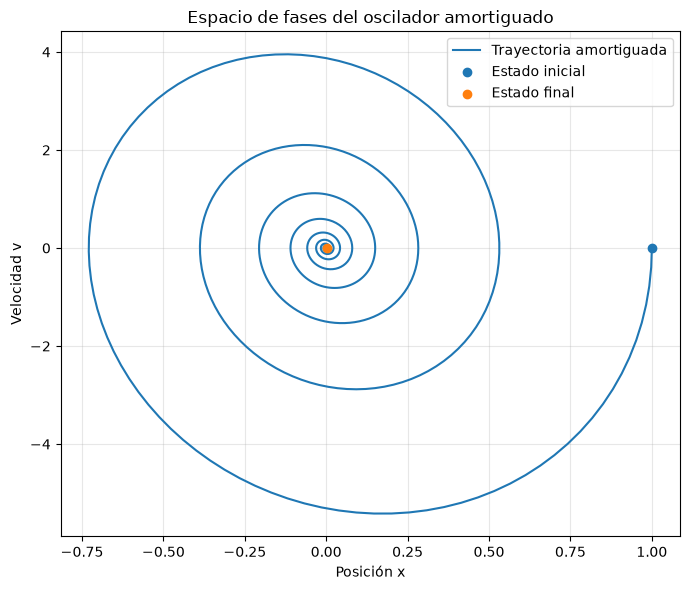

In [20]:
plt.figure(figsize=(7, 6))

plt.plot(
    damped_position,
    damped_velocity,
    label="Trayectoria amortiguada",
)

plt.scatter(
    damped_position[0],
    damped_velocity[0],
    label="Estado inicial",
    zorder=3,
)

plt.scatter(
    damped_position[-1],
    damped_velocity[-1],
    label="Estado final",
    zorder=3,
)

plt.xlabel("Posición x")
plt.ylabel("Velocidad v")
plt.title("Espacio de fases del oscilador amortiguado")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
damped_energy = (
    0.5 * damped_velocity**2
    + 0.5 * omega_0**2 * damped_position**2
)

normalized_damped_energy = (
    damped_energy / damped_energy[0]
)

print(f"Energía inicial: {damped_energy[0]:.10f}")
print(f"Energía final: {damped_energy[-1]:.10f}")
print(
    "Fracción de energía restante:",
    f"{normalized_damped_energy[-1]:.3e}",
)

Energía inicial: 19.7392088022
Energía final: 0.0000648954
Fracción de energía restante: 3.288e-06


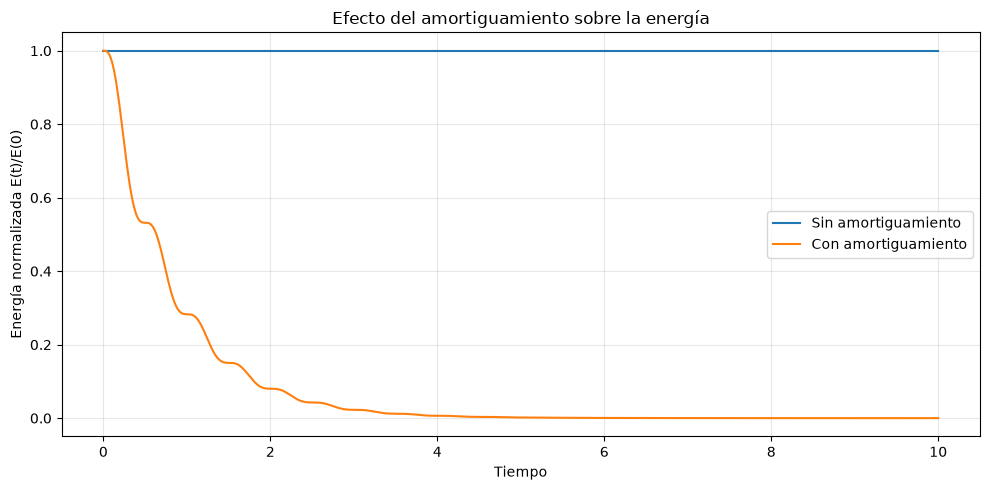

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    time,
    energy / energy[0],
    label="Sin amortiguamiento",
)

plt.plot(
    damped_time,
    normalized_damped_energy,
    label="Con amortiguamiento",
)

plt.xlabel("Tiempo")
plt.ylabel("Energía normalizada E(t)/E(0)")
plt.title("Efecto del amortiguamiento sobre la energía")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
energy_increments = np.diff(damped_energy)

maximum_energy_increase = np.max(energy_increments)

print(
    "Máximo incremento numérico de energía:",
    f"{maximum_energy_increase:.3e}",
)

Máximo incremento numérico de energía: -1.918e-09


In [24]:
assert damped_solution.success
assert max_damped_position_error < 1e-7
assert damped_energy[-1] < damped_energy[0]
assert maximum_energy_increase < 1e-8

print("VALIDACIÓN DEL OSCILADOR AMORTIGUADO SUPERADA")

VALIDACIÓN DEL OSCILADOR AMORTIGUADO SUPERADA


## 3. Oscilador de Duffing no forzado

La ecuación estudiada es:

\[
\ddot{x}
+2\zeta\omega_0\dot{x}
+\omega_0^2x
+\alpha x^3
=0.
\]

Como sistema de primer orden:

\[
\dot{x}=v,
\]

\[
\dot{v}
=
-2\zeta\omega_0v
-\omega_0^2x
-\alpha x^3.
\]

El parámetro \(\alpha\) controla la no linealidad cúbica:

- \(\alpha=0\): oscilador lineal amortiguado.
- \(\alpha>0\): endurecimiento de la fuerza restauradora.
- \(\alpha<0\): ablandamiento de la fuerza restauradora, con posibles
  cambios cualitativos del potencial según los parámetros.

In [28]:
def duffing_oscillator(
    t,
    state,
    omega,
    damping_ratio,
    alpha,
):
    """
    Oscilador de Duffing amortiguado y sin forzamiento.

    Ecuación:
        x'' + 2*zeta*omega*x' + omega^2*x + alpha*x^3 = 0

    Parámetros
    ----------
    t : float
        Tiempo.
    state : array-like
        Estado [x, v].
    omega : float
        Frecuencia angular del término lineal.
    damping_ratio : float
        Razón de amortiguamiento zeta.
    alpha : float
        Coeficiente de la no linealidad cúbica.

    Retorna
    -------
    list
        Derivadas [dx/dt, dv/dt].
    """
    x, v = state

    dx_dt = v

    dv_dt = (
        -2.0 * damping_ratio * omega * v
        - omega**2 * x
        - alpha * x**3
    )

    return [dx_dt, dv_dt]


In [29]:
alpha_linear_control = 0.0

duffing_linear_solution = solve_ivp(
    fun=duffing_oscillator,
    t_span=(t_start, t_end),
    y0=initial_state,
    t_eval=t_eval,
    args=(
        omega_0,
        damping_ratio,
        alpha_linear_control,
    ),
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)

duffing_linear_position = duffing_linear_solution.y[0]
duffing_linear_velocity = duffing_linear_solution.y[1]

linear_position_difference = np.max(
    np.abs(
        duffing_linear_position
        - damped_position
    )
)

linear_velocity_difference = np.max(
    np.abs(
        duffing_linear_velocity
        - damped_velocity
    )
)

print(
    "Diferencia máxima en posición:",
    f"{linear_position_difference:.3e}",
)

print(
    "Diferencia máxima en velocidad:",
    f"{linear_velocity_difference:.3e}",
)

Diferencia máxima en posición: 0.000e+00
Diferencia máxima en velocidad: 0.000e+00


In [30]:
assert duffing_linear_solution.success
assert linear_position_difference < 1e-10
assert linear_velocity_difference < 1e-10

print("CONTROL LINEAL DE DUFFING SUPERADO")

CONTROL LINEAL DE DUFFING SUPERADO


In [31]:
alpha_duffing = 100.0

duffing_solution = solve_ivp(
    fun=duffing_oscillator,
    t_span=(t_start, t_end),
    y0=initial_state,
    t_eval=t_eval,
    args=(
        omega_0,
        damping_ratio,
        alpha_duffing,
    ),
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)

print("Integración exitosa:", duffing_solution.success)
print("Mensaje:", duffing_solution.message)

duffing_time = duffing_solution.t
duffing_position = duffing_solution.y[0]
duffing_velocity = duffing_solution.y[1]

Integración exitosa: True
Mensaje: The solver successfully reached the end of the integration interval.


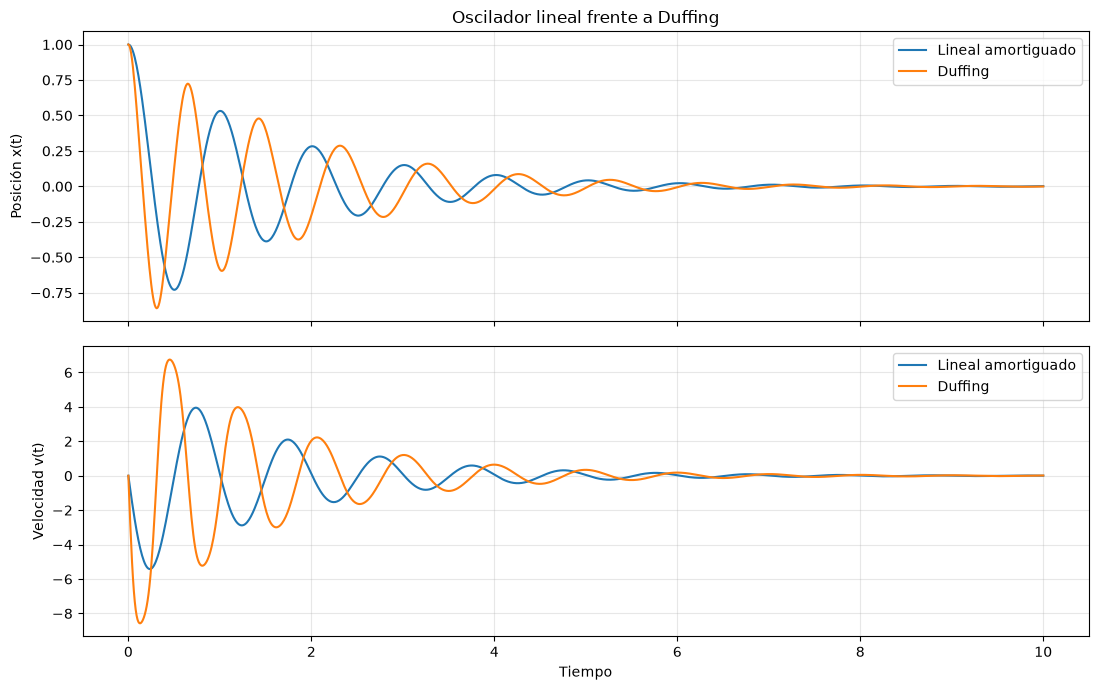

In [32]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(11, 7),
    sharex=True,
)

axes[0].plot(
    damped_time,
    damped_position,
    label="Lineal amortiguado",
)

axes[0].plot(
    duffing_time,
    duffing_position,
    label="Duffing",
)

axes[0].set_ylabel("Posición x(t)")
axes[0].set_title(
    "Oscilador lineal frente a Duffing"
)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    damped_time,
    damped_velocity,
    label="Lineal amortiguado",
)

axes[1].plot(
    duffing_time,
    duffing_velocity,
    label="Duffing",
)

axes[1].set_xlabel("Tiempo")
axes[1].set_ylabel("Velocidad v(t)")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

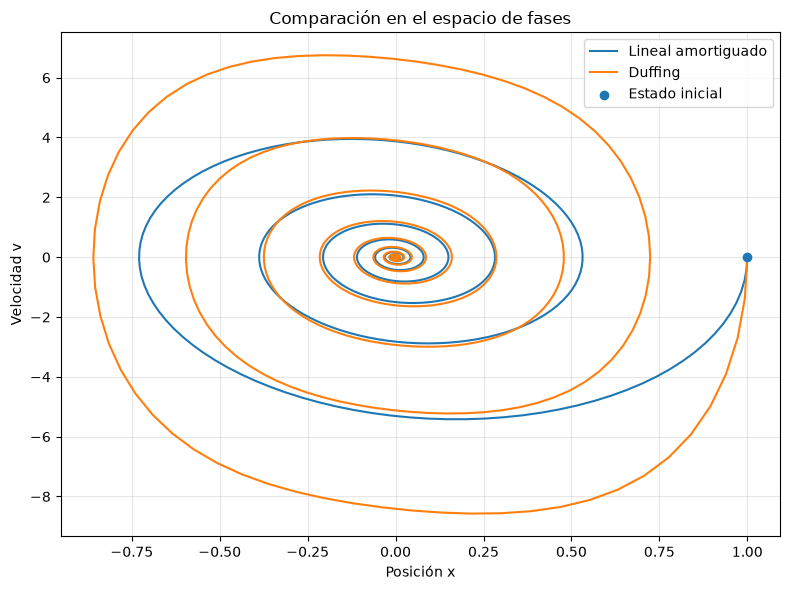

In [33]:
plt.figure(figsize=(8, 6))

plt.plot(
    damped_position,
    damped_velocity,
    label="Lineal amortiguado",
)

plt.plot(
    duffing_position,
    duffing_velocity,
    label="Duffing",
)

plt.scatter(
    duffing_position[0],
    duffing_velocity[0],
    label="Estado inicial",
    zorder=3,
)

plt.xlabel("Posición x")
plt.ylabel("Velocidad v")
plt.title("Comparación en el espacio de fases")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
duffing_energy = (
    0.5 * duffing_velocity**2
    + 0.5 * omega_0**2 * duffing_position**2
    + 0.25 * alpha_duffing * duffing_position**4
)

normalized_duffing_energy = (
    duffing_energy / duffing_energy[0]
)

duffing_energy_increments = np.diff(
    duffing_energy
)

maximum_duffing_energy_increase = np.max(
    duffing_energy_increments
)

print(
    f"Energía inicial: {duffing_energy[0]:.10f}"
)

print(
    f"Energía final: {duffing_energy[-1]:.10f}"
)

print(
    "Fracción de energía restante:",
    f"{normalized_duffing_energy[-1]:.3e}",
)

print(
    "Máximo incremento numérico de energía:",
    f"{maximum_duffing_energy_increase:.3e}",
)

Energía inicial: 44.7392088022
Energía final: 0.0001168427
Fracción de energía restante: 2.612e-06
Máximo incremento numérico de energía: -1.190e-09


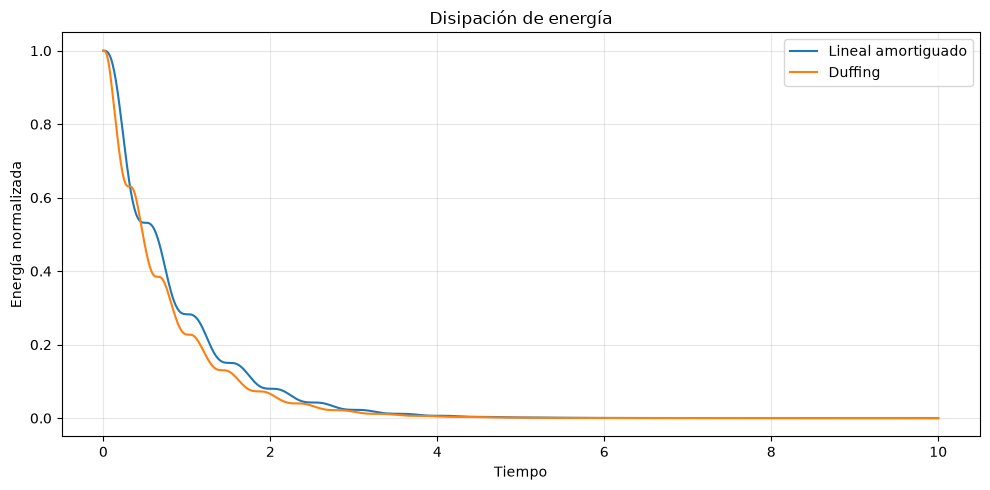

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(
    damped_time,
    damped_energy / damped_energy[0],
    label="Lineal amortiguado",
)

plt.plot(
    duffing_time,
    normalized_duffing_energy,
    label="Duffing",
)

plt.xlabel("Tiempo")
plt.ylabel("Energía normalizada")
plt.title("Disipación de energía")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
theoretical_energy_derivative = (
    -2.0
    * damping_ratio
    * omega_0
    * duffing_velocity**2
)

numerical_energy_derivative = np.gradient(
    duffing_energy,
    duffing_time,
)

energy_derivative_rmse = np.sqrt(
    np.mean(
        (
            numerical_energy_derivative
            - theoretical_energy_derivative
        )**2
    )
)

print(
    "RMSE de la derivada de energía:",
    f"{energy_derivative_rmse:.3e}",
)

RMSE de la derivada de energía: 6.139e-02


In [37]:
assert duffing_solution.success
assert duffing_energy[-1] < duffing_energy[0]
assert maximum_duffing_energy_increase < 1e-7
assert np.all(np.isfinite(duffing_position))
assert np.all(np.isfinite(duffing_velocity))

print("VALIDACIÓN DE DUFFING NO FORZADO SUPERADA")

VALIDACIÓN DE DUFFING NO FORZADO SUPERADA


## 4. Oscilador de Duffing amortiguado y forzado

La ecuación diferencial estudiada es:

\[
\ddot{x}
+2\zeta\omega_0\dot{x}
+\omega_0^2x
+\alpha x^3
=
A\cos(\Omega t).
\]

Como sistema de primer orden:

\[
\dot{x}=v,
\]

\[
\dot{v}
=
-2\zeta\omega_0v
-\omega_0^2x
-\alpha x^3
+A\cos(\Omega t).
\]

Este sistema es no autónomo porque depende explícitamente del tiempo.

El balance de energía contiene dos contribuciones:

\[
\frac{dE}{dt}
=
-2\zeta\omega_0v^2
+
A\cos(\Omega t)v.
\]

El primer término disipa energía y el segundo puede introducirla o extraerla
dependiendo de la fase relativa entre la fuerza y la velocidad.

In [38]:
def forced_duffing_oscillator(
    t,
    state,
    omega,
    damping_ratio,
    alpha,
    forcing_amplitude,
    forcing_frequency,
):
    """
    Oscilador de Duffing amortiguado y forzado.

    Ecuación:
        x'' + 2*zeta*omega*x' + omega^2*x + alpha*x^3
        = A*cos(Omega*t)

    El estado es [x, v].
    """
    x, v = state

    forcing = (
        forcing_amplitude
        * np.cos(forcing_frequency * t)
    )

    dx_dt = v

    dv_dt = (
        -2.0 * damping_ratio * omega * v
        - omega**2 * x
        - alpha * x**3
        + forcing
    )

    return [dx_dt, dv_dt]

In [39]:
zero_forcing_amplitude = 0.0
forcing_frequency_control = omega_0

forced_duffing_control = solve_ivp(
    fun=forced_duffing_oscillator,
    t_span=(t_start, t_end),
    y0=initial_state,
    t_eval=t_eval,
    args=(
        omega_0,
        damping_ratio,
        alpha_duffing,
        zero_forcing_amplitude,
        forcing_frequency_control,
    ),
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)

forced_control_position = forced_duffing_control.y[0]
forced_control_velocity = forced_duffing_control.y[1]

forced_control_position_difference = np.max(
    np.abs(
        forced_control_position
        - duffing_position
    )
)

forced_control_velocity_difference = np.max(
    np.abs(
        forced_control_velocity
        - duffing_velocity
    )
)

print(
    "Diferencia máxima en posición:",
    f"{forced_control_position_difference:.3e}",
)

print(
    "Diferencia máxima en velocidad:",
    f"{forced_control_velocity_difference:.3e}",
)

assert forced_duffing_control.success
assert forced_control_position_difference < 1e-10
assert forced_control_velocity_difference < 1e-10

print("CONTROL SIN FORZAMIENTO SUPERADO")

Diferencia máxima en posición: 0.000e+00
Diferencia máxima en velocidad: 0.000e+00
CONTROL SIN FORZAMIENTO SUPERADO


In [40]:
forcing_amplitude = 20.0
forcing_frequency = 6.0

forcing_period = (
    2 * np.pi / forcing_frequency
)

print(
    f"Amplitud del forzamiento: {forcing_amplitude:.6f}"
)

print(
    f"Frecuencia del forzamiento: {forcing_frequency:.6f}"
)

print(
    f"Periodo del forzamiento: {forcing_period:.6f}"
)

print(
    "Razón frecuencia de forzamiento / frecuencia natural:",
    f"{forcing_frequency / omega_0:.6f}",
)

Amplitud del forzamiento: 20.000000
Frecuencia del forzamiento: 6.000000
Periodo del forzamiento: 1.047198
Razón frecuencia de forzamiento / frecuencia natural: 0.954930


In [41]:
forced_t_start = 0.0
forced_t_end = 50.0
forced_dt = 0.01

forced_t_eval = np.arange(
    forced_t_start,
    forced_t_end + forced_dt,
    forced_dt,
)

print(
    "Número de puntos del sistema forzado:",
    len(forced_t_eval),
)

Número de puntos del sistema forzado: 5001


In [42]:
forced_duffing_solution = solve_ivp(
    fun=forced_duffing_oscillator,
    t_span=(forced_t_start, forced_t_end),
    y0=initial_state,
    t_eval=forced_t_eval,
    args=(
        omega_0,
        damping_ratio,
        alpha_duffing,
        forcing_amplitude,
        forcing_frequency,
    ),
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)

print(
    "Integración exitosa:",
    forced_duffing_solution.success,
)

print(
    "Mensaje:",
    forced_duffing_solution.message,
)

forced_time = forced_duffing_solution.t
forced_position = forced_duffing_solution.y[0]
forced_velocity = forced_duffing_solution.y[1]

print("Puntos calculados:", len(forced_time))
print(
    "Rango de posición:",
    f"[{forced_position.min():.6f}, "
    f"{forced_position.max():.6f}]",
)

print(
    "Rango de velocidad:",
    f"[{forced_velocity.min():.6f}, "
    f"{forced_velocity.max():.6f}]",
)

Integración exitosa: True
Mensaje: The solver successfully reached the end of the integration interval.
Puntos calculados: 5001
Rango de posición: [-0.754801, 1.000000]
Rango de velocidad: [-7.187107, 4.810817]


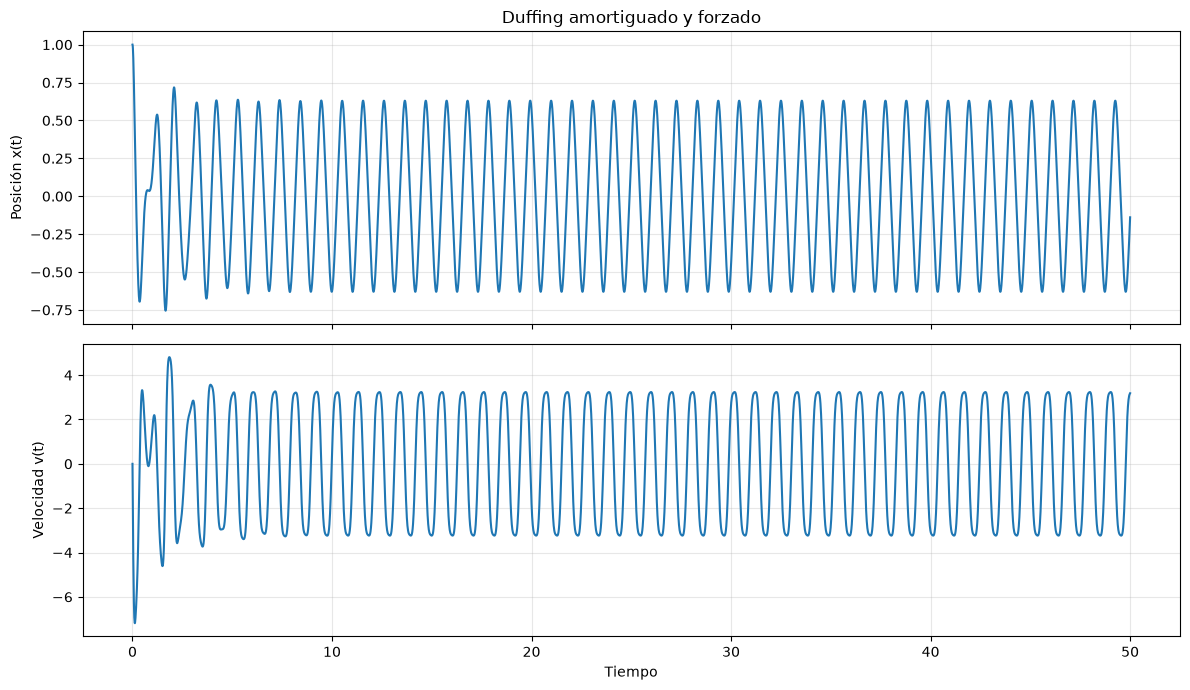

In [43]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 7),
    sharex=True,
)

axes[0].plot(
    forced_time,
    forced_position,
)

axes[0].set_ylabel("Posición x(t)")
axes[0].set_title(
    "Duffing amortiguado y forzado"
)
axes[0].grid(alpha=0.3)

axes[1].plot(
    forced_time,
    forced_velocity,
)

axes[1].set_xlabel("Tiempo")
axes[1].set_ylabel("Velocidad v(t)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [44]:
transient_end_time = 25.0

steady_mask = forced_time >= transient_end_time

steady_time = forced_time[steady_mask]
steady_position = forced_position[steady_mask]
steady_velocity = forced_velocity[steady_mask]

print(
    "Puntos en el régimen tardío:",
    len(steady_time),
)

print(
    "Amplitud aproximada tardía:",
    f"{0.5 * np.ptp(steady_position):.6f}",
)

Puntos en el régimen tardío: 2501
Amplitud aproximada tardía: 0.630282


In [45]:
0.5 * np.ptp(steady_position)

np.float64(0.6302819541453994)

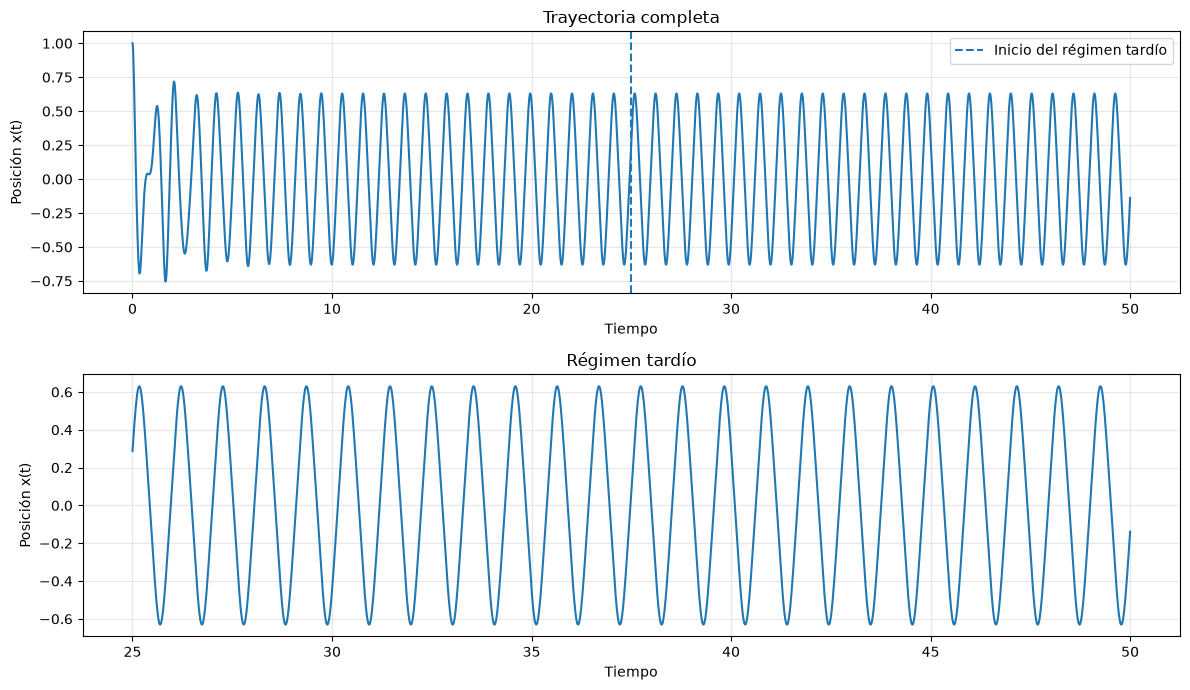

In [46]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 7),
)

axes[0].plot(
    forced_time,
    forced_position,
)

axes[0].axvline(
    transient_end_time,
    linestyle="--",
    label="Inicio del régimen tardío",
)

axes[0].set_xlabel("Tiempo")
axes[0].set_ylabel("Posición x(t)")
axes[0].set_title("Trayectoria completa")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    steady_time,
    steady_position,
)

axes[1].set_xlabel("Tiempo")
axes[1].set_ylabel("Posición x(t)")
axes[1].set_title("Régimen tardío")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

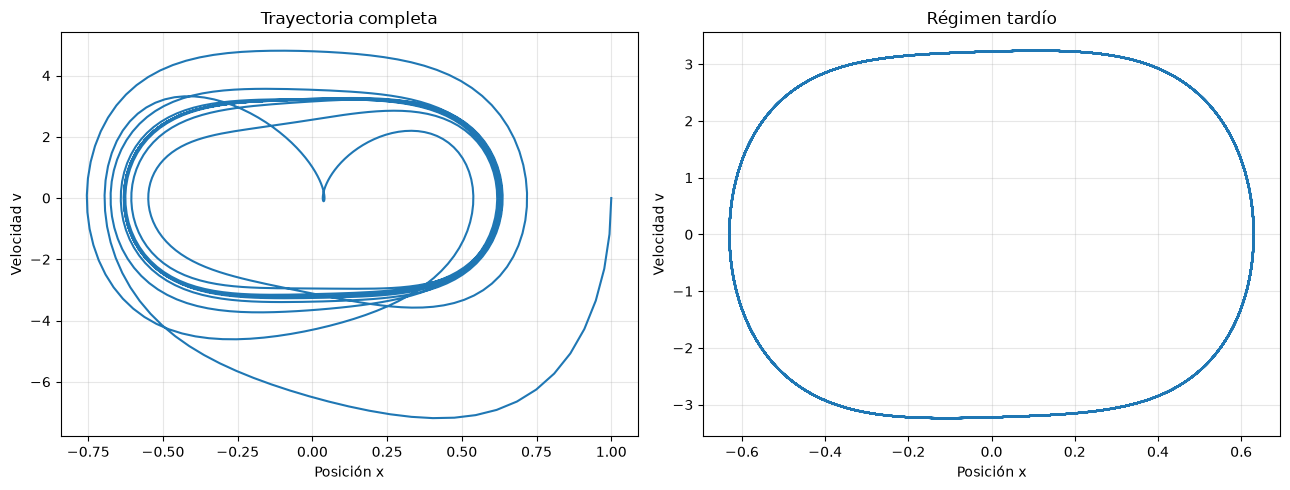

In [47]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5),
)

axes[0].plot(
    forced_position,
    forced_velocity,
)

axes[0].set_xlabel("Posición x")
axes[0].set_ylabel("Velocidad v")
axes[0].set_title("Trayectoria completa")
axes[0].grid(alpha=0.3)

axes[1].plot(
    steady_position,
    steady_velocity,
)

axes[1].set_xlabel("Posición x")
axes[1].set_ylabel("Velocidad v")
axes[1].set_title("Régimen tardío")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
forced_energy = (
    0.5 * forced_velocity**2
    + 0.5 * omega_0**2 * forced_position**2
    + 0.25 * alpha_duffing * forced_position**4
)

forced_energy_increments = np.diff(forced_energy)

positive_energy_increments = np.sum(
    forced_energy_increments > 0
)

negative_energy_increments = np.sum(
    forced_energy_increments < 0
)

print(
    f"Energía mínima: {forced_energy.min():.10f}"
)

print(
    f"Energía máxima: {forced_energy.max():.10f}"
)

print(
    "Intervalos con aumento de energía:",
    positive_energy_increments,
)

print(
    "Intervalos con disminución de energía:",
    negative_energy_increments,
)

Energía mínima: 0.0237113952
Energía máxima: 44.7392088022
Intervalos con aumento de energía: 2513
Intervalos con disminución de energía: 2487


In [60]:
dissipation_power = (
    -2.0
    * damping_ratio
    * omega_0
    * forced_velocity**2
)

forcing_power = (
    forcing_amplitude
    * np.cos(forcing_frequency * forced_time)
    * forced_velocity
)

theoretical_forced_energy_derivative = (
    dissipation_power + forcing_power
)

numerical_forced_energy_derivative = np.gradient(
    forced_energy,
    forced_time,
)

forced_energy_derivative_rmse = np.sqrt(
    np.mean(
        (
            numerical_forced_energy_derivative
            - theoretical_forced_energy_derivative
        )**2
    )
)

interior_slice = slice(1, -1)

interior_forced_energy_derivative_rmse = np.sqrt(
    np.mean(
        (
            numerical_forced_energy_derivative[interior_slice]
            - theoretical_forced_energy_derivative[interior_slice]
        )**2
    )
)

print(
    "RMSE total del balance energético:",
    f"{forced_energy_derivative_rmse:.3e}"
)

print(
    "RMSE interior del balance energético:",
    f"{interior_forced_energy_derivative_rmse:.3e}",
)

RMSE total del balance energético: 1.954e-01
RMSE interior del balance energético: 8.086e-02
